# Duration-specific calibration: coefficient maps and leave-one-out evaluation

For each gradient duration:

1. **Calibration maps** - the coefficient maps fitted to all repeats (as saved by `estimate_calibration.py`):
   their distribution across the mask and an axial slice of each.
2. **Leave-one-out evaluation** - repeat *k* of every sequence is held out in fold *k*, calibration maps are fitted to the
   other repeats of that duration only (`cal.loo_bmap_predictions`), and used to predict the b-value maps of the
   held-out scans. The measured, predicted and corrected (measured / predicted) correction-factor maps are shown for
   each sequence, with the distribution of the measured and corrected maps over all folds.

The scans are the noisy scans (`config.SCAN_TYPE`), so the training and test data are independent. The per-scan b-value
and smoothed gradient maps are read from the cache written by `estimate_calibration.py`.

In [2]:
# Project settings and paths: config.py is in the project root (this also makes the modules in src/ importable)
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())))
import config

# General libraries
import json
import numpy as np
import pandas as pd
import nibabel as nib

# Plotting libraries
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import colorcet

# Custom functions
import registration as reg
import calib_utils as cal

config.RESULTS_PLOT_DIR.mkdir(parents=True, exist_ok=True)

### LOAD DATA

In [3]:
# Sequence parameters and the mask
df = pd.read_hdf(config.PARAM_FNAME, key="df", mode="r")
df["row"] = np.arange(df.shape[0]) # position in the parameter file, scan files and cached maps

# Per-scan maps from estimate_calibration.py. Volume i is row i of the parameter file.
bmap_nii = nib.load(config.BMAP_FNAME)
gmap2_nii = nib.load(config.GMAP2_FNAME)
scan_aff = bmap_nii.affine
scan_spacing = reg.spacing_from_affine(scan_aff)

for nii in (bmap_nii, gmap2_nii):
    meta = json.loads(next(e for e in nii.header.extensions if e.get_code() == 40).content.decode("utf-8"))
    if meta["scan_type"] != config.SCAN_TYPE or meta["spline_param"] != config.SPLINE_PARAM:
        raise ValueError(f"Cached maps were made with scan type {meta['scan_type']} and spline_param {meta['spline_param']}; "
                         f"config has {config.SCAN_TYPE} and {config.SPLINE_PARAM} - re-run estimate_calibration.py")

bmap_4d = bmap_nii.get_fdata()
gmap2_4d = gmap2_nii.get_fdata()

preprocess_mask = nib.load(config.MASK_FNAME).get_fdata().astype(bool)

# Create a mask slightly inset from threshold based mask to avoid boundary artefacts.
core_mask = cal.shrink_mask_mm(preprocess_mask, voxel_spacing=scan_spacing, margin_mm=config.SHRINK_DIST_MM)

# Diffusion-weighted scans (those with maps in the cache), in order of scan time
is_dwi = np.array([lab["is_dwi"] for lab in meta["volume_labels"]])
dwi_df = df[is_dwi].copy()
dwi_df.sort_values("scan_time", inplace=True, ignore_index=True)

dwi_df["bmap"] = dwi_df["row"].apply(lambda i: bmap_4d[..., i])
dwi_df["gmap2_bspline"] = dwi_df["row"].apply(lambda i: gmap2_4d[..., i].astype(np.float32))
dwi_df["cmap"] = dwi_df["bmap"] / dwi_df["b_value"]

### CALIBRATION MAPS

In [4]:
def plot_calibration_maps(A_img, dur):
    """
    Plot the calibration maps of one gradient duration: the distributions across the mask and an axial slice
    of the quadratic (relative to their mean) and linear coefficient maps for each direction.
    """

    # -------------------------
    # Split data
    # -------------------------
    A_q = A_img[..., 3:]
    A_l = A_img[..., :3]

    # Deviations
    A_q_avg = np.mean(A_q[core_mask == 1], axis=0)
    A_l_avg = np.mean(A_l[core_mask == 1], axis=0)
    print(A_q_avg)
    print("C_G minimum in the mask:", A_q[core_mask == 1].min())

    A_q_dev = np.zeros_like(A_q)
    A_l_dev = np.zeros_like(A_l)

    A_q_dev[core_mask == 1] = A_q[core_mask == 1] - A_q_avg

    # -------------------------
    # Layout
    # -------------------------
    fig = plt.figure(figsize=(16, 7))
    gs = fig.add_gridspec(
        2, 5,
        width_ratios=[2.5, 1, 1, 1, 0.1],
        wspace=0.25,
        hspace=0.75
    )

    ax_kde = [fig.add_subplot(gs[i, 0]) for i in range(2)]
    ax_im = [[fig.add_subplot(gs[i, j]) for j in range(1, 4)] for i in range(2)]
    cax = [fig.add_subplot(gs[i, 4]) for i in range(2)]

    # -------------------------
    # Settings
    # -------------------------
    kde_xlim = (-4e-5, 12e-5) # same range for both distributions so their variation can be compared
    i_slice = A_img.shape[2] // 2
    kde_colors = plt.get_cmap("Blues")(np.linspace(0.5, 0.9, 3))

    # -------------------------
    # KDE plots
    # -------------------------
    for i in range(3):
        sns.kdeplot(
            A_q[..., i][core_mask == 1],
            clip=kde_xlim,
            color=kde_colors[i],
            ax=ax_kde[0],
            lw=0.8,
            label="XYZ"[i]
        )

        sns.kdeplot(
            A_l[..., i][core_mask == 1],
            clip=kde_xlim,
            color=kde_colors[i],
            ax=ax_kde[1],
            lw=0.8,
            label="XYZ"[i]
        )

    for i, ax in enumerate(ax_kde):
        ax.set_ylabel("Density", fontstyle="italic", fontsize=10, rotation=0)
        ax.yaxis.set_label_coords(-0.08, 1.)
        ax.set_ylim(0, 80000)
        ax.set_yticks(np.linspace(0, 70000, num=8, endpoint=True))
        ax.set_xlim(kde_xlim)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x * 1e5:g}")) # in units of 1e-5
        ax.grid(alpha=0.25)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(labelsize=10)
        ax.legend(frameon=False, fontsize=10)

    # No axis labels (the rows are labelled); just the units of the tick labels
    for ax in ax_kde:
        ax.set_xlabel(r"$(\times 10^{-5})$", fontsize=12)

    # -------------------------
    # Shared image scaling
    # -------------------------
    lim = np.max([
        np.abs(A_q_dev[core_mask == 1]).max(),
        np.abs(A_l_dev[core_mask == 1]).max()
    ]) * 1e5

    # -------------------------
    # Image plotting helper
    # -------------------------
    def plot_row(ax_list, data, cmap, vmin, vmax):
        ims = []
        for i, ax in enumerate(ax_list):

            sl = data[:, :, i_slice, i] * 1e5
            sl = np.rot90(sl, k=1)[:, 7:-8]

            mask = np.rot90(core_mask[:, :, i_slice], k=1)[:, 7:-8]
            overlay = np.full_like(sl, np.nan)
            overlay[mask == 0] = 1

            im = ax.imshow(sl, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.imshow(overlay, cmap="Greys_r", vmin=0, vmax=1)

            ax.set_axis_off()
            ims.append(im)

        return ims[-1]

    # -------------------------
    # Plot rows
    # -------------------------
    # C_G is positive everywhere, so its scale runs from zero using the red half of the coolwarm colour map
    coolwarm_reds = LinearSegmentedColormap.from_list("coolwarm_reds", colorcet.cm.coolwarm(np.linspace(0.5, 1, 256)))
    # Each row has its own colour scale (in units of 1e-5): C_G (top) from 2 to 10, the linear coefficients (bottom) +/- 4
    im_top = plot_row(ax_im[0], A_q, cmap=colorcet.cm.coolwarm, vmin=2, vmax=10)
    im_bot = plot_row(ax_im[1], A_l, cmap=colorcet.cm.coolwarm, vmin=-4, vmax=4)

    # -------------------------
    # Colorbar
    # -------------------------
    for im, cax_i in zip([im_top, im_bot], cax):
        cbar = fig.colorbar(im, cax=cax_i)
        cbar.ax.set_title("$\\times 10^{-5}$", fontsize=12, pad=10)
        cbar.ax.tick_params(labelsize=12)

    # -------------------------
    # Tighten the maps. They are taller than wide, so the equal-aspect images do not fill their grid cells, which leaves
    # large gaps between them. Lay out the section right of the divider explicitly: the divider sits a fixed distance
    # right of the distributions, followed by the maps with the same spacing either side and then the colourbars.
    # -------------------------
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    tight = lambda a: inv.transform_bbox(a.get_tightbbox(renderer))

    edge_gap = 0.03    # divider to distributions and divider to maps (figure fraction)
    map_gap = 0.022    # between maps
    cbar_gap = 0.03    # last map to colourbar
    map_drop = 0.03    # the maps and colourbars sit this far below the top of their section

    img_pos = ax_im[0][0].get_position()    # active position after the aspect ratio has been applied: the size of the image
    x_first = max(tight(a).x1 for a in ax_kde) + 2 * edge_gap
    x_cbar = x_first + 3 * img_pos.width + 2 * map_gap + cbar_gap

    for row in range(2):
        for col, ax in enumerate(ax_im[row]):
            p = ax.get_position()
            ax.set_position([x_first + col * (img_pos.width + map_gap), p.y0 - map_drop, img_pos.width, p.height])
        p = cax[row].get_position()
        cax[row].set_position([x_cbar, p.y0 - map_drop, p.width, p.height])

    # -------------------------
    # Row labels
    # -------------------------
    row_labels = [r"$C_G$", r"$C_X$"]

    for i in range(2):
        # use full row span (all axes in that row)
        row_axes = [ax_kde[i]] + ax_im[i]

        y0 = min(ax.get_position().y0 for ax in row_axes)
        y1 = max(ax.get_position().y1 for ax in row_axes)
        y_center = (y0 + y1) / 2

        # place safely left of ALL axes (not just KDE)
        x_left = min(ax.get_position().x0 for ax in row_axes)

        fig.text(
            x_left - 0.06,   # <- key spacing control
            y_center,
            row_labels[i],
            rotation=0,
            va="center",
            ha="center",
            fontsize=20
        )

    # -------------------------
    # Column headers
    # -------------------------
    col_labels = ["X", "Y", "Z"]
    for ax_row in ax_im:    # above both rows of maps (the first three texts made here are the top row, used for the labels below)
        for i, ax in enumerate(ax_row):
            pos = ax.get_position()
            fig.text(
                pos.x0 + pos.width / 2,
                pos.y1 + 0.02,
                col_labels[i],
                ha="center",
                va="bottom",
                fontsize=20
            )

    # -------------------------
    # Dashed separators and panel labels (A-D: left to right, top to bottom)
    # -------------------------
    fig.canvas.draw()
    extent = lambda t: inv.transform_bbox(t.get_window_extent(renderer))

    row_txts, head_txts = fig.texts[:2], fig.texts[2:5]    # the row labels and the column headers made above
    x_left = min(extent(t).x0 for t in row_txts)
    y_top = max(extent(t).y1 for t in head_txts) + map_drop    # the top of the section: where the headers were before the maps moved down
    x_right = max(tight(c).x1 for c in cax)
    y_bottom = min(tight(a).y0 for a in ax_kde + cax)

    # Vertical: halfway between the right edge of the distributions (with their tick labels) and the maps
    x_div = (max(tight(a).x1 for a in ax_kde) + min(a.get_position().x0 for row in ax_im for a in row)) / 2

    # Horizontal: halfway between the lowest element of the top row (x labels) and the highest of the bottom row
    # ("Density" label and colourbar title)
    top_row_low = min(tight(a).y0 for a in [ax_kde[0], cax[0]] + ax_im[0])
    bottom_row_high = max([tight(a).y1 for a in [ax_kde[1], cax[1]] + ax_im[1]] + [extent(t).y1 for t in fig.texts[5:8]])
    y_div = (top_row_low + bottom_row_high) / 2

    # The vertical line is split in two, leaving a gap where it would cross the (continuous) horizontal line
    cross_gap = 0.02
    for y_a, y_b in [(y_bottom, y_div - cross_gap), (y_div + cross_gap, y_top)]:
        fig.add_artist(Line2D([x_div, x_div], [y_a, y_b], transform=fig.transFigure, color="black", linestyle="--", linewidth=1.2))
    fig.add_artist(Line2D([x_left, x_right], [y_div, y_div], transform=fig.transFigure, color="black", linestyle="--", linewidth=1.2))

    label_gap = 0.012
    lower_label_gap = 0.035    # the lower labels (C, D) sit further below the horizontal line
    for letter, x, y in [("A", x_left, y_top), ("B", x_div + label_gap, y_top),
                         ("C", x_left, y_div - lower_label_gap), ("D", x_div + label_gap, y_div - lower_label_gap)]:
        fig.text(x, y, letter, fontsize=20, fontweight="bold", ha="left", va="top")

    fmt="png"
    plot_fname = config.RESULTS_PLOT_DIR / f"calibration_CMAPS_DUR_{int(round(dur*1e3))}.{fmt}"
    fig.savefig(fname=plot_fname, dpi=600, format=fmt, bbox_inches='tight', pad_inches=0.12)
    plt.show()

[0.0001394  0.00013779 0.0001458 ]
C_G minimum in the mask: 6.408529305544954e-05


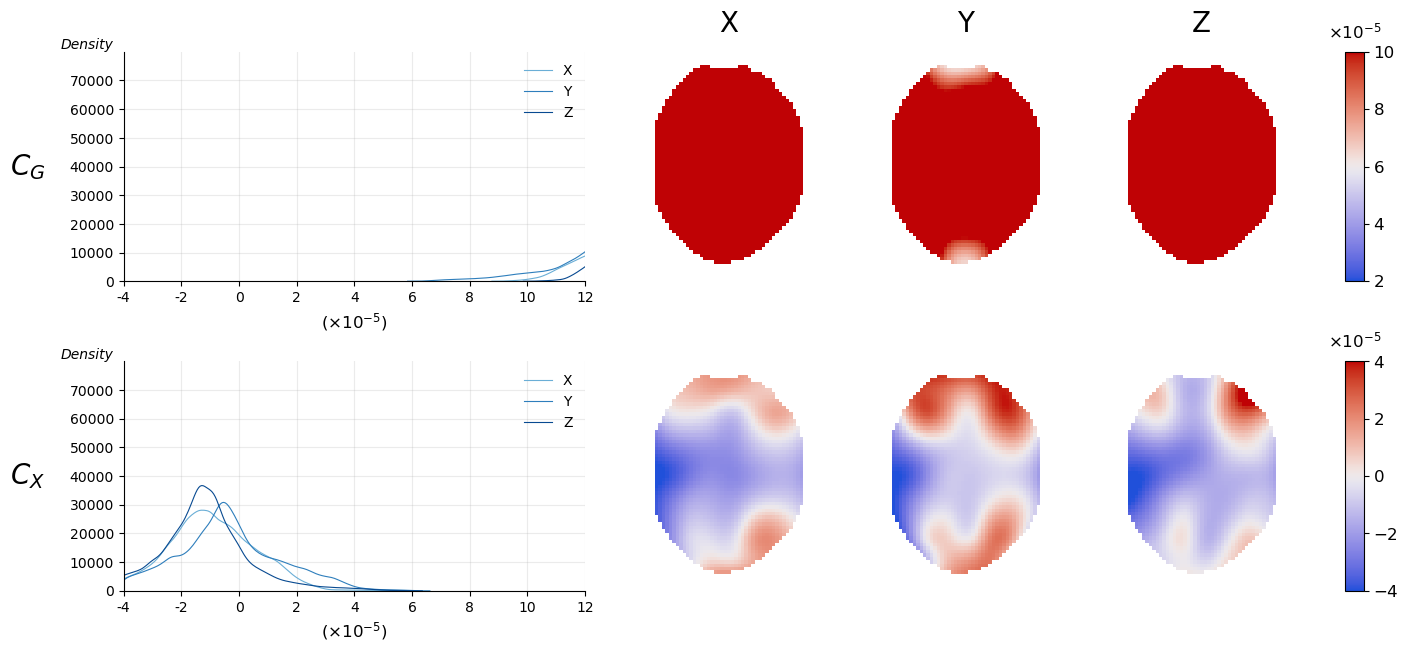

[1.03459298e-04 8.80690927e-05 8.19234281e-05]
C_G minimum in the mask: 4.052940714831249e-05


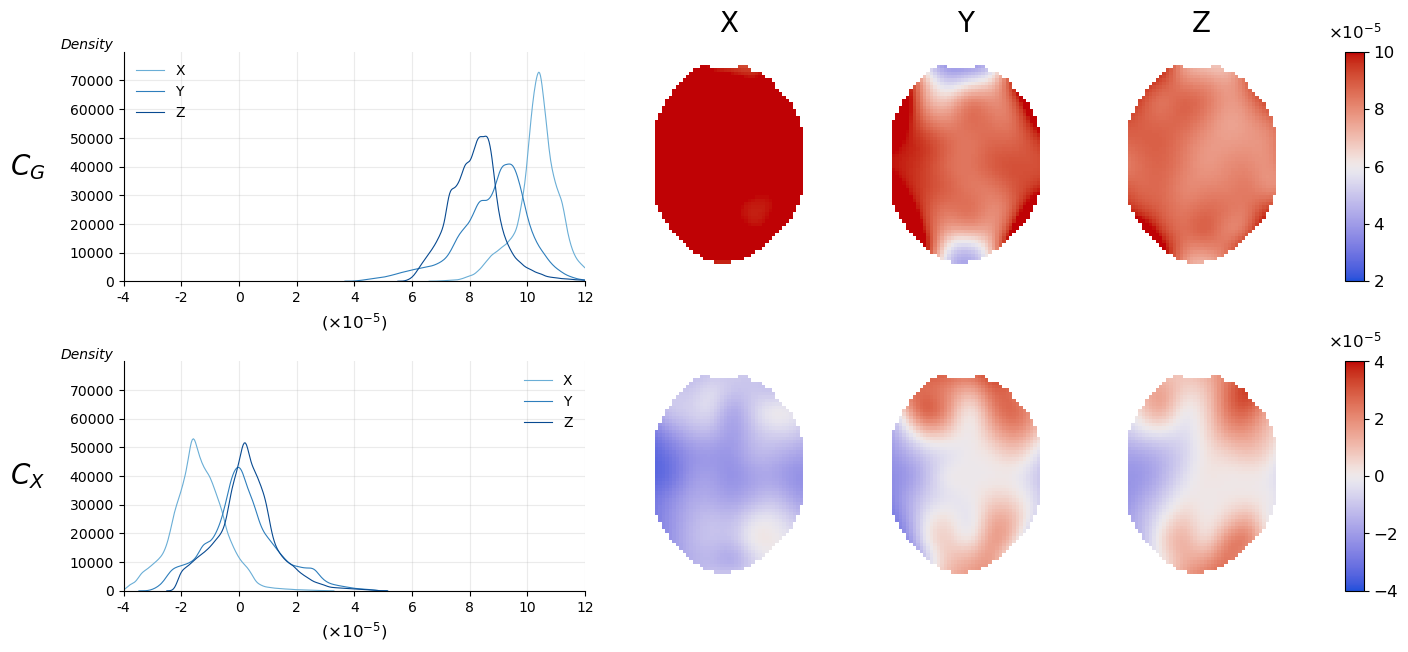

[6.05635960e-05 6.04915234e-05 5.85766577e-05]
C_G minimum in the mask: 2.7589727609171603e-05


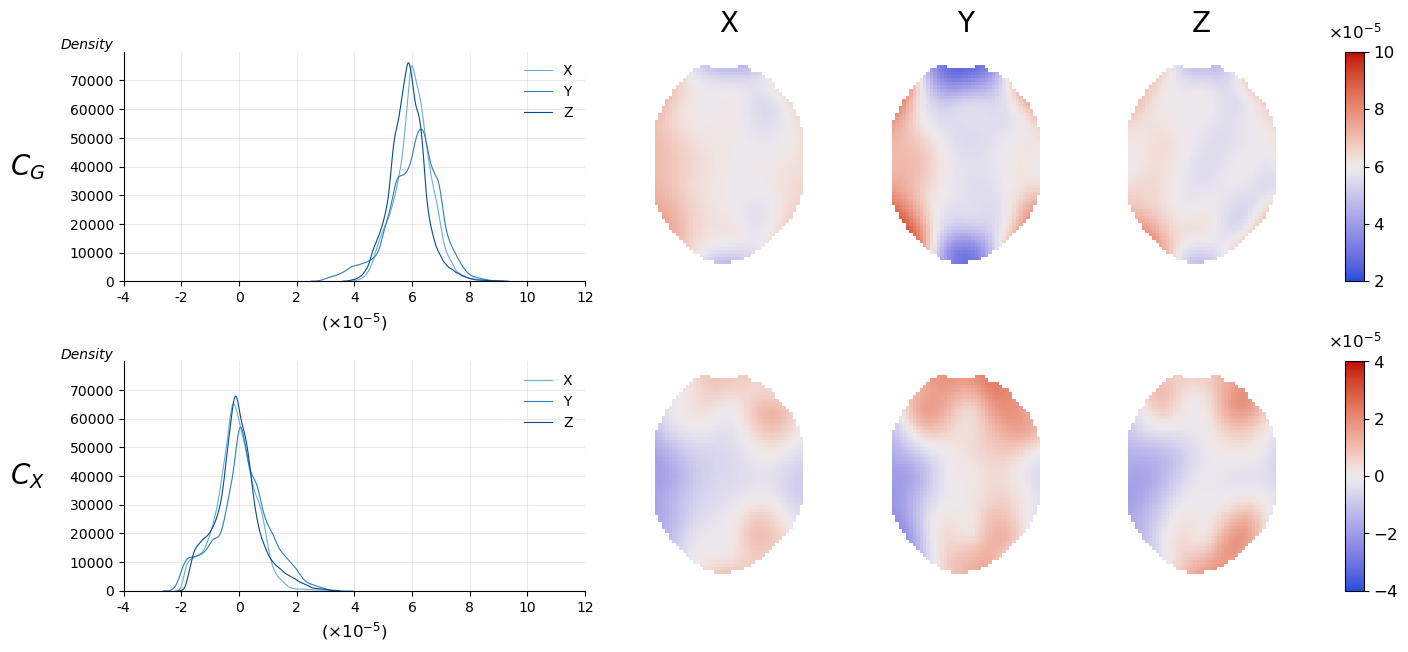

In [5]:
for dur in sorted(dwi_df["dwi_grad_duration"].unique()):

    A_img = nib.load(config.a_dur_fname(dur)).get_fdata()
    plot_calibration_maps(A_img, dur)

### LEAVE-ONE-OUT

In [6]:
# -----------------------------------------------------------------------------
# Leave-one-out across repeats: repeat k of every sequence is held out in fold k.
# Calibration maps are fitted to the other repeats of the same gradient duration.
# -----------------------------------------------------------------------------
pred_df = cal.loo_bmap_predictions(dwi_df, core_mask, levels=["duration"])

LOO fold 1/6
LOO fold 2/6
LOO fold 3/6
LOO fold 4/6
LOO fold 5/6
LOO fold 6/6


In [7]:
# -----------------------------------------------------------------------------
# Organise the results by sequence and repeat
# -----------------------------------------------------------------------------
dwi_df["repeat_idx"] = dwi_df.groupby("seq_name").cumcount()

# Number of repeats available per sequence
repeat_counts = dwi_df.groupby("seq_name").size()
n_repeats = repeat_counts.min()

# Consistent sequence ordering
seq_order = sorted(dwi_df["seq_name"].unique())
dur_order = [float(seq[-2:]) for seq in seq_order]
dw_axis_order = [seq[5].upper() for seq in seq_order]
bval_order = [int(seq[7:10]) for seq in seq_order]
n_seq = len(seq_order)

# Stored as (X, Y, Z, n_seq, n_repeats)
measured_all = np.zeros((*core_mask.shape, n_seq, n_repeats), dtype=np.float32)
predicted_all = np.zeros_like(measured_all)
corrected_all = np.zeros_like(measured_all)

for idx in pred_df.index:

    row = dwi_df.loc[idx]
    i_seq = seq_order.index(row["seq_name"])
    i_rep = row["repeat_idx"]

    eval_cmap = row["cmap"].astype(np.float32)
    pred_cmap = (pred_df.at[idx, "pred_bmap_duration"] / row["b_value"]).astype(np.float32)

    corr_cmap = np.zeros_like(eval_cmap, dtype=np.float32)
    valid_mask = (eval_cmap > 0) & (pred_cmap > 0) & (core_mask == 1)
    corr_cmap[valid_mask] = eval_cmap[valid_mask] / pred_cmap[valid_mask]

    measured_all[..., i_seq, i_rep] = eval_cmap
    predicted_all[..., i_seq, i_rep] = pred_cmap
    corrected_all[..., i_seq, i_rep] = corr_cmap

# Average across LOO folds for imshow
mean_measured = np.mean(measured_all, axis=-1)
mean_predicted = np.mean(predicted_all, axis=-1)
mean_corrected = np.mean(corrected_all, axis=-1)

### FIGURES

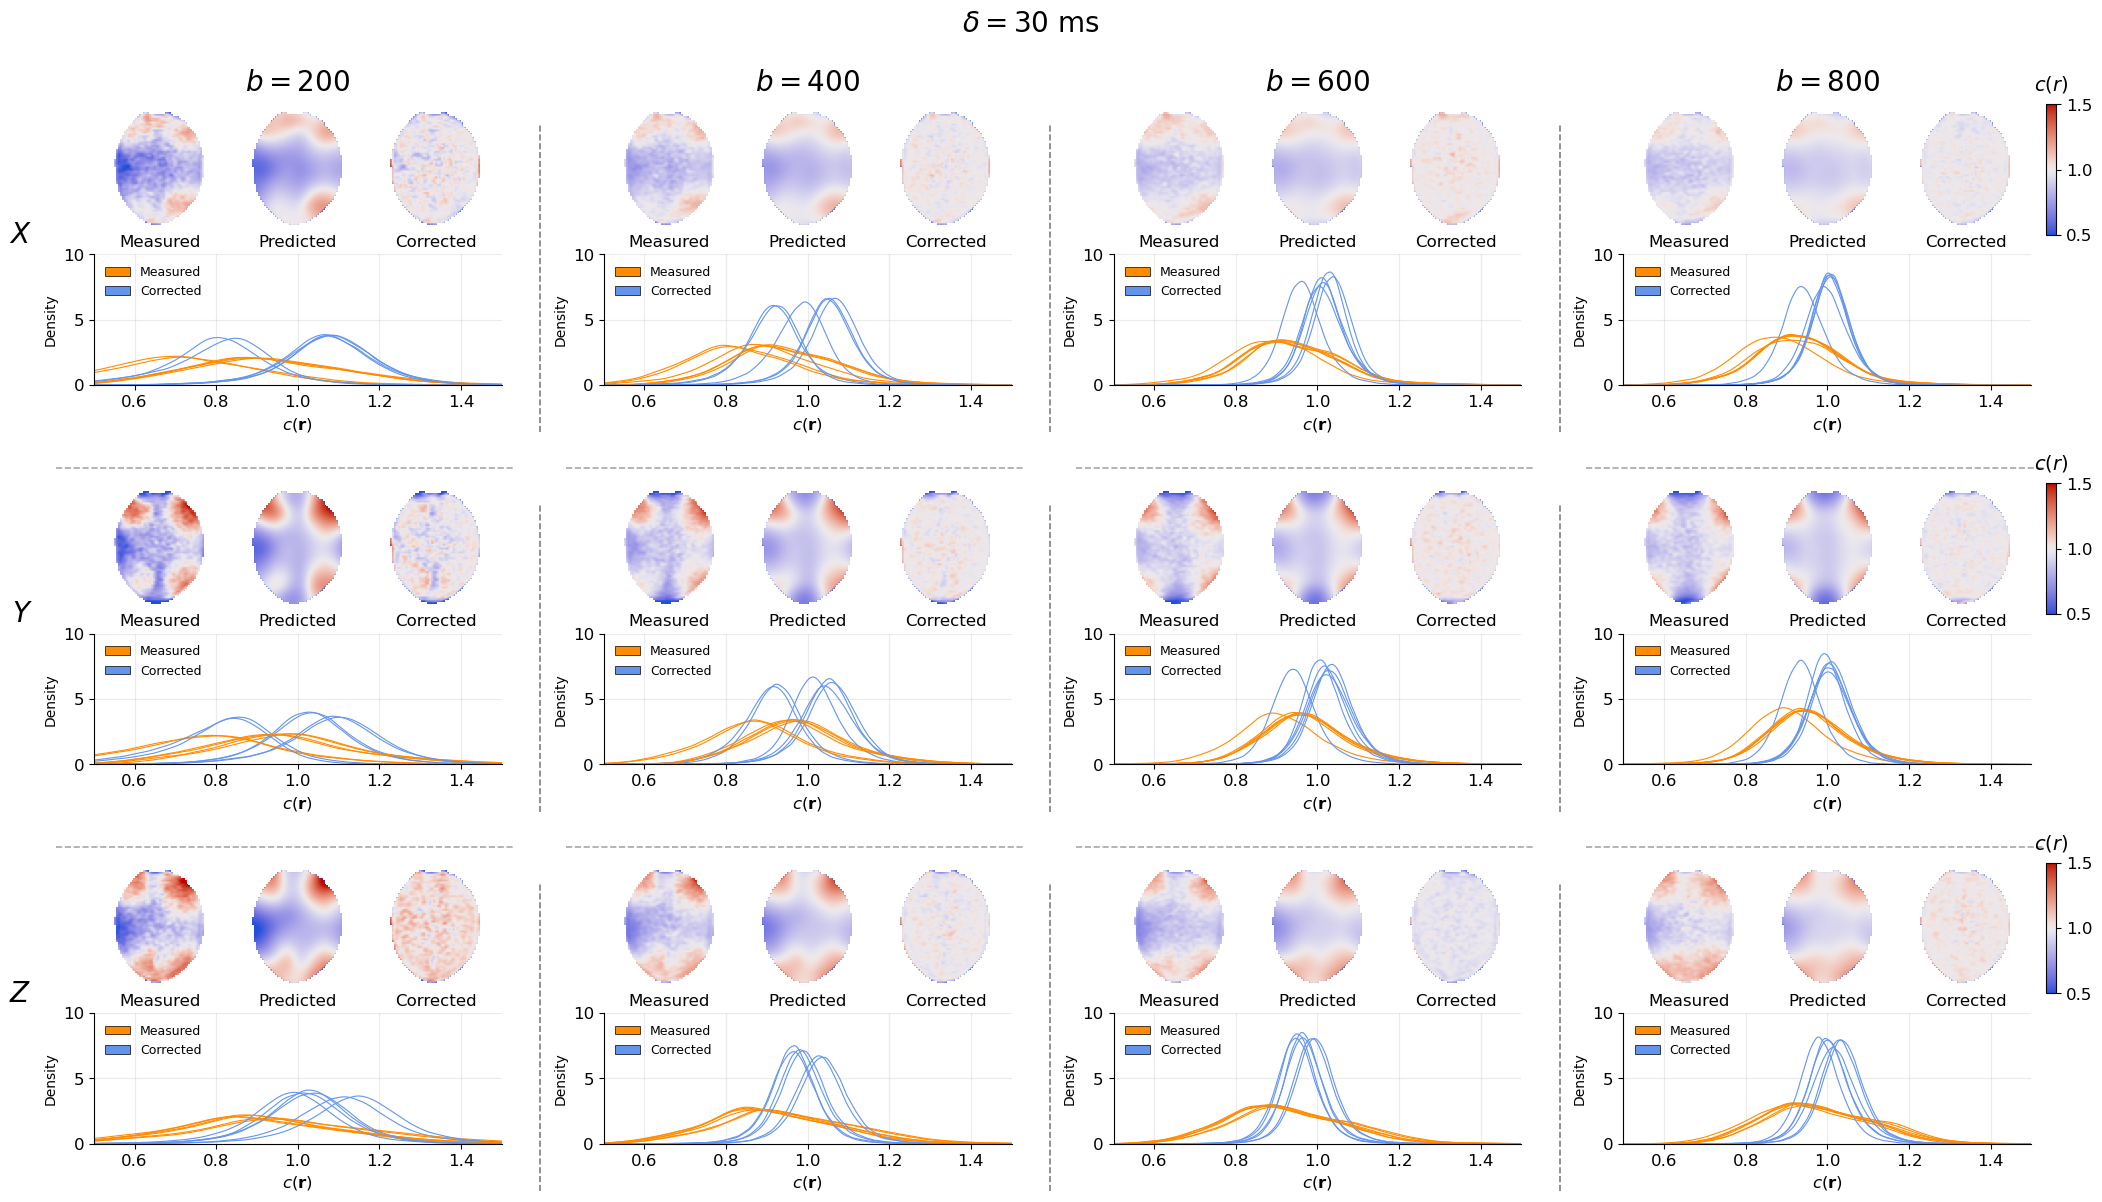

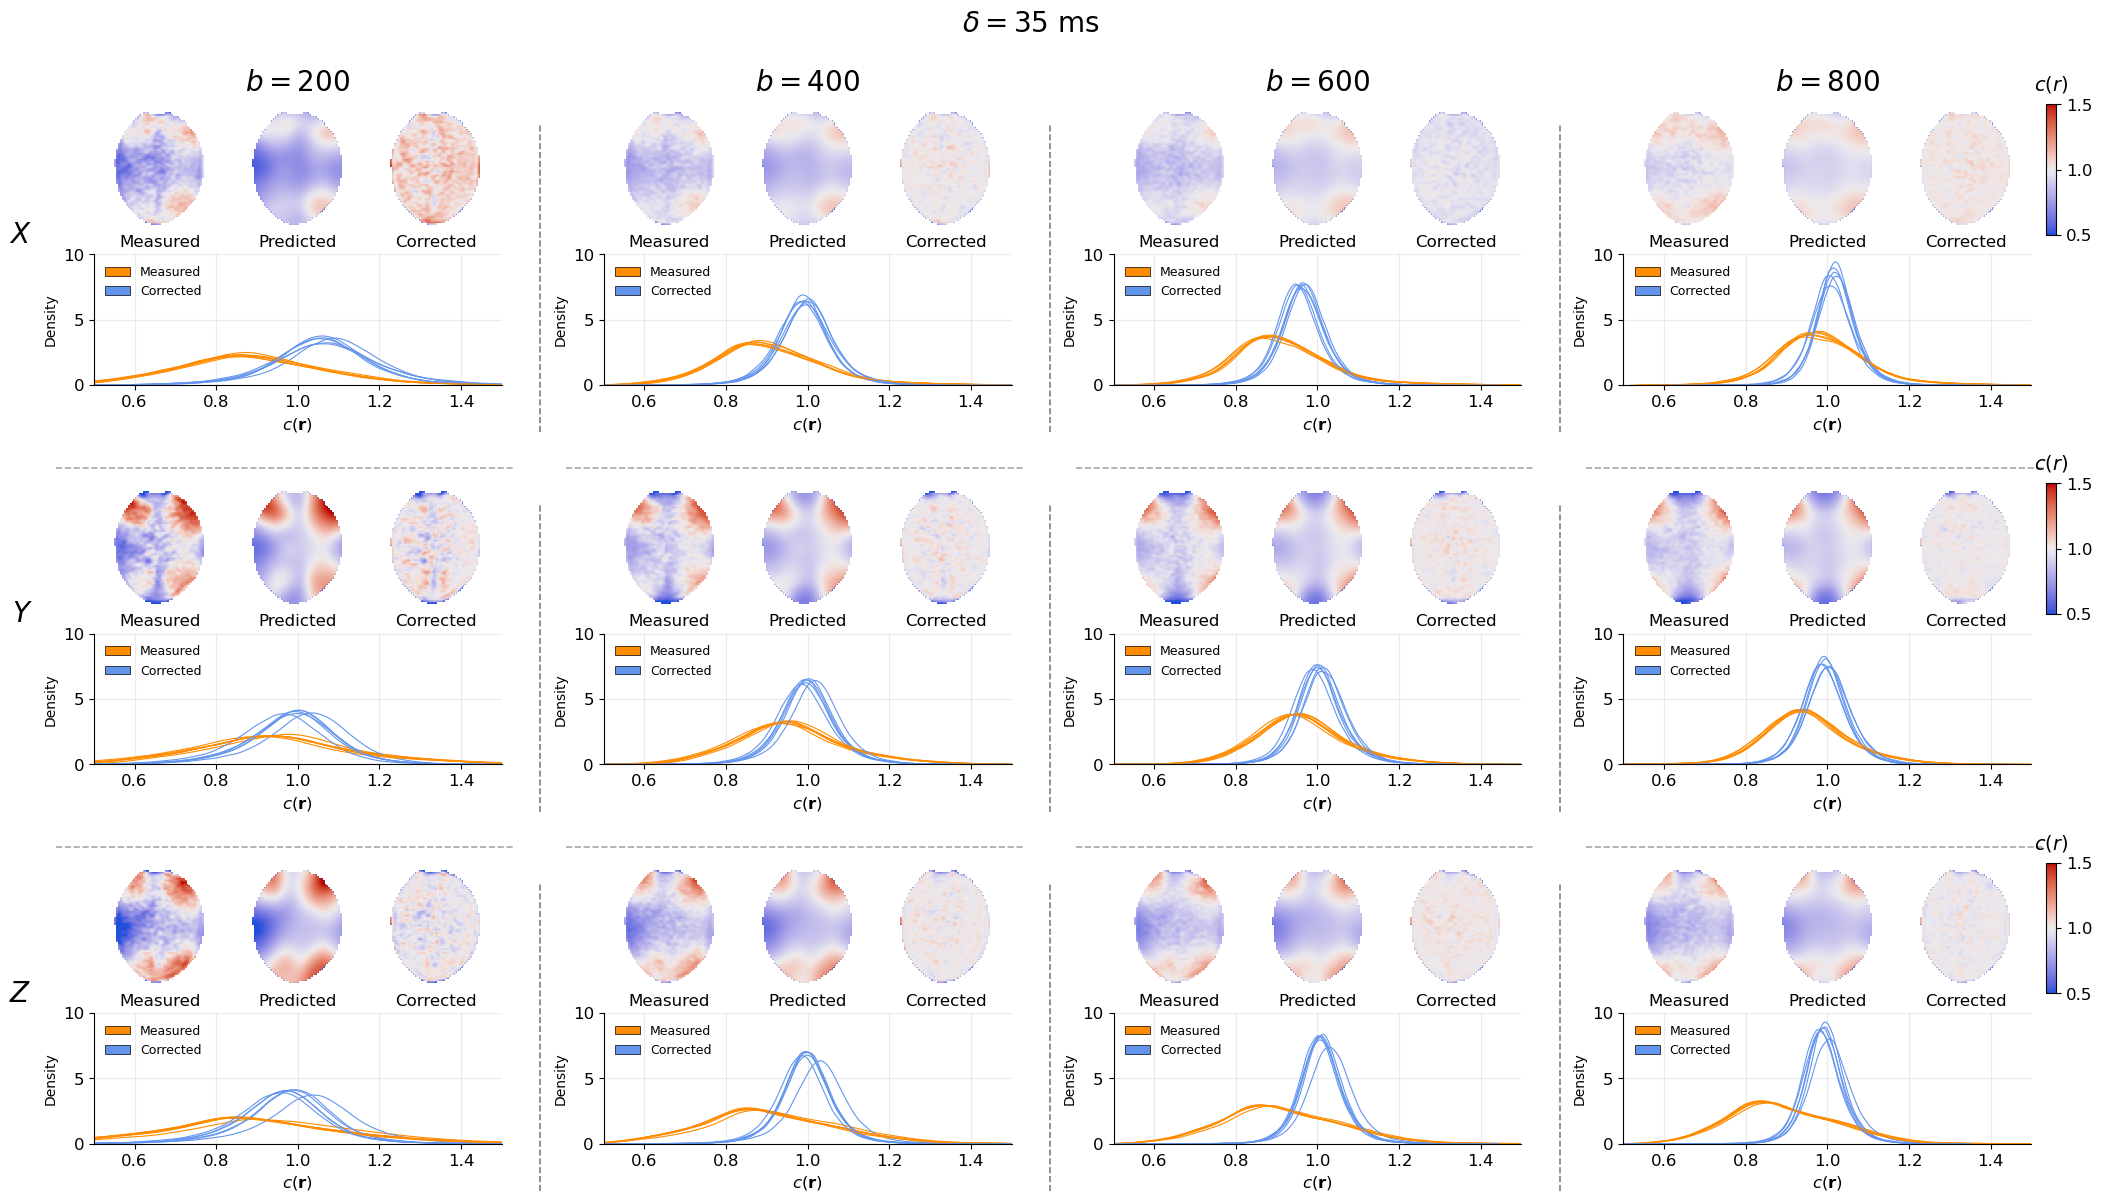

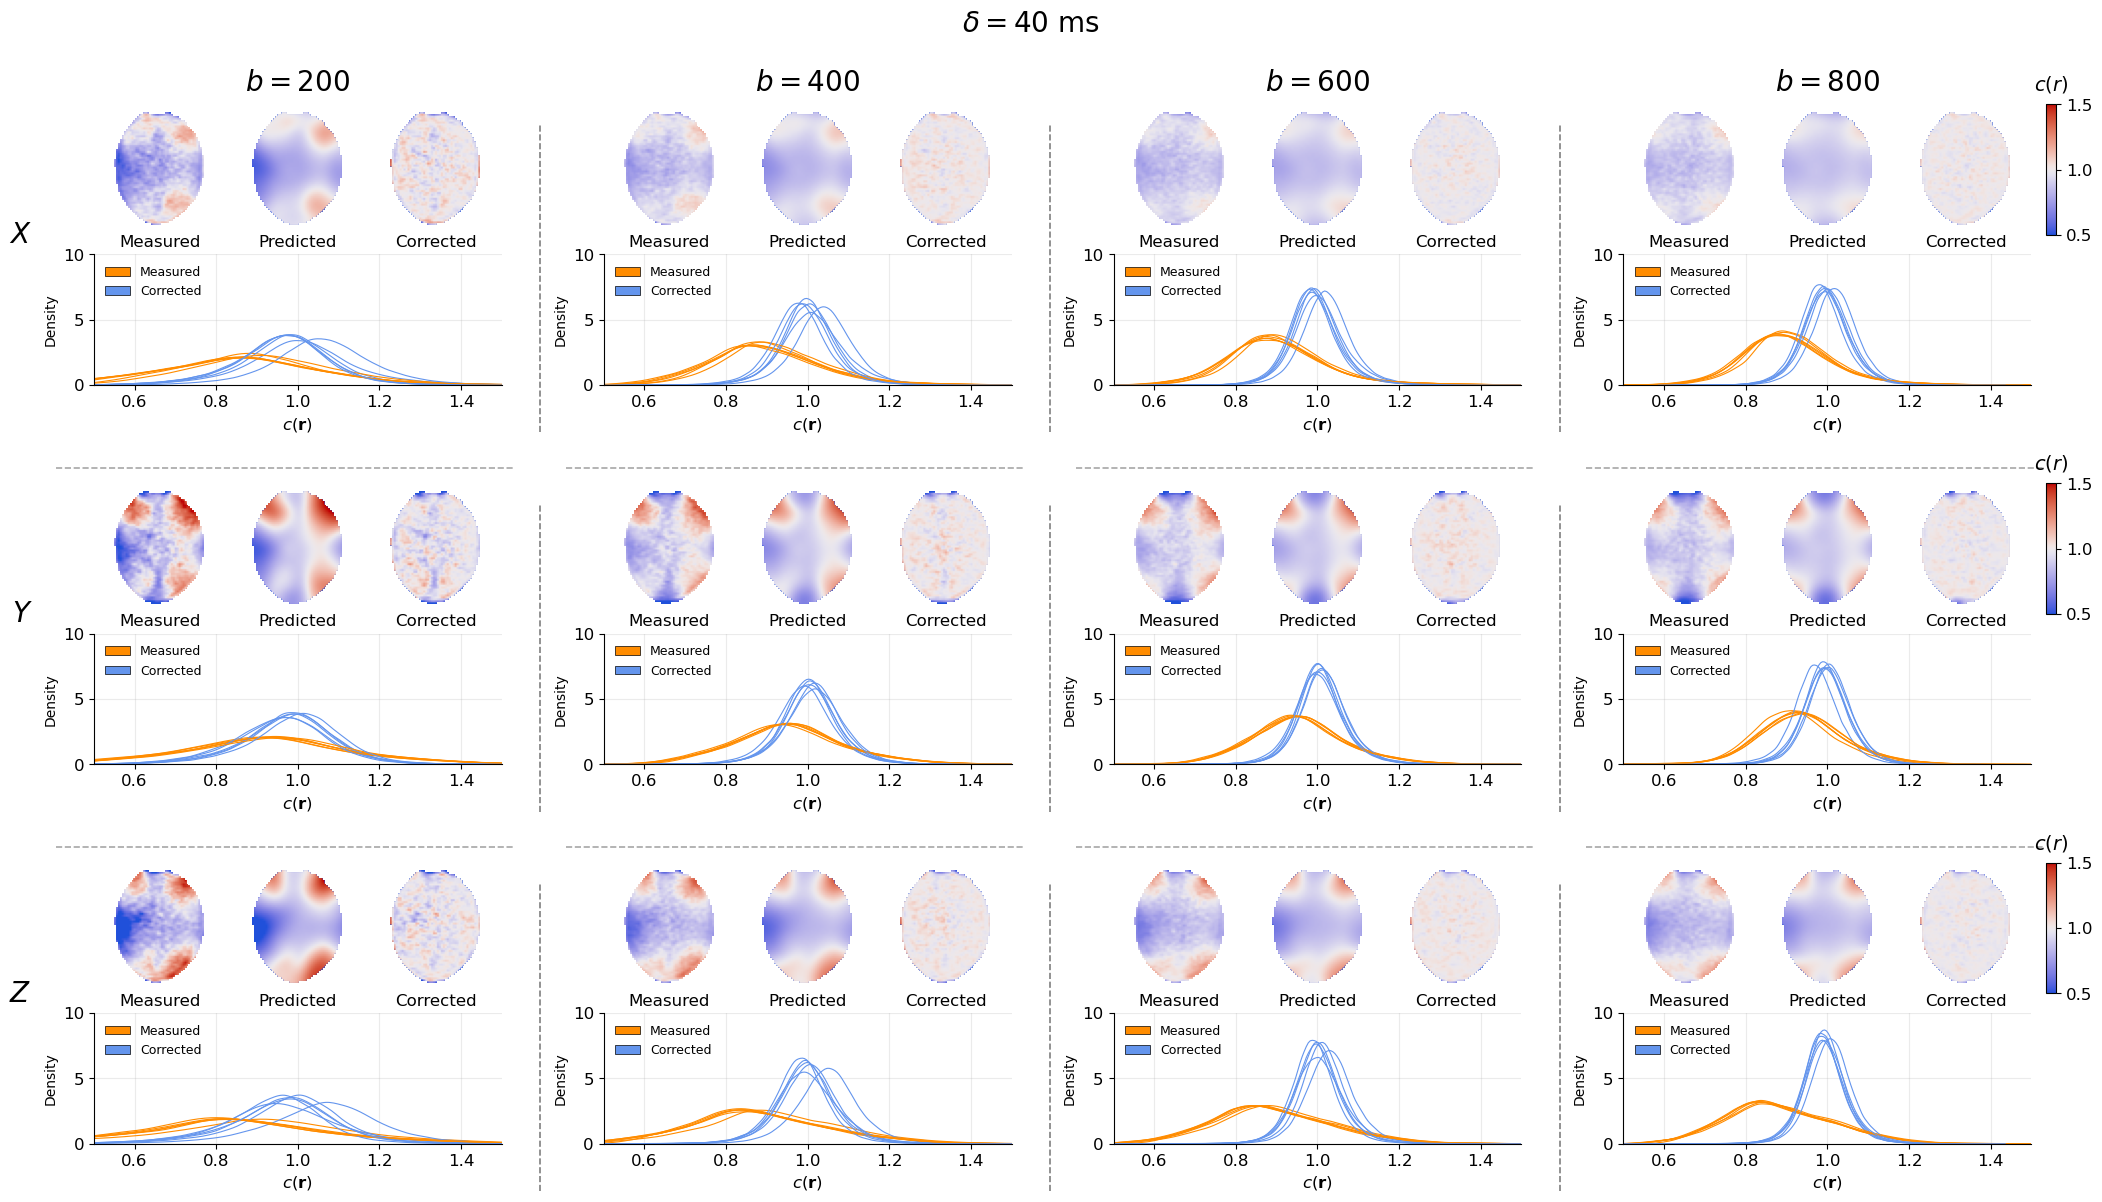

In [8]:
i_slice = mean_measured.shape[2] // 2
lim = 0.5

# -------------------------
# Layout assumptions
# -------------------------
n_figures = 3          # rows (X, Y, Z)
seq_per_figure = 4    # columns

# -------------------------
# Consistent font settings
# -------------------------
fs_seq_title = 20
fs_im_title = 12
fs_ticks = 12
fs_legend = 9
fs_cbar = 14
kde_lw = 0.8

for dur in np.unique(dur_order):

    i_dur = np.where(np.array(dur_order) == dur)[0]

    dur_seq_order = [seq_order[i] for i in i_dur]
    dur_dw_axis_order = [dw_axis_order[i] for i in i_dur]
    dur_bval_order = [bval_order[i] for i in i_dur]

    dur_measured = mean_measured[..., i_dur]
    dur_predicted = mean_predicted[..., i_dur]
    dur_corrected = mean_corrected[..., i_dur]

    dur_measured_all = measured_all[..., i_dur, :]
    dur_corrected_all = corrected_all[..., i_dur, :]

    # -------------------------
    # Create ONE figure per duration
    # -------------------------
    fig = plt.figure(figsize=(25, 4.5 * n_figures))

    outer_gs = fig.add_gridspec(
        n_figures, seq_per_figure,
        wspace=0.25,
        hspace=0.35
    )

    # -------------------------
    # Loop over rows (axes)
    # -------------------------
    for fig_idx in range(n_figures):

        seq_start = fig_idx * seq_per_figure
        seq_end = seq_start + seq_per_figure

        image_axes_row = []
        last_im = None

        # -------------------------
        # Loop over columns (b-values)
        # -------------------------
        for j, i_seq in enumerate(range(seq_start, seq_end)):

            inner_gs = outer_gs[fig_idx, j].subgridspec(
                2, 3,
                hspace=0.15,
                wspace=0.05
            )

            ax1 = fig.add_subplot(inner_gs[0, 0])
            ax2 = fig.add_subplot(inner_gs[0, 1])
            ax3 = fig.add_subplot(inner_gs[0, 2])
            ax4 = fig.add_subplot(inner_gs[1, :])

            meas = np.rot90(dur_measured[:, :, i_slice, i_seq], k=1)[:, :-1]
            pred = np.rot90(dur_predicted[:, :, i_slice, i_seq], k=1)[:, :-1]
            corr = np.rot90(dur_corrected[:, :, i_slice, i_seq], k=1)[:, :-1]

            mask_slice = np.rot90(core_mask[:, :, i_slice], k=1)[:, :-1]
            plot_mask = np.full_like(meas, np.nan, dtype=float)
            plot_mask[mask_slice == 0] = 1

            im_axes = [ax1, ax2, ax3]
            im_data = [meas, pred, corr]
            im_labels = ["Measured", "Predicted", "Residual"]

            for ax, data, lab in zip(im_axes, im_data, im_labels):
                im = ax.imshow(
                    data,
                    vmin=1 - lim,
                    vmax=1 + lim,
                    cmap=colorcet.cm.coolwarm,
                    interpolation=None
                )

                ax.imshow(
                    plot_mask,
                    vmin=0,
                    vmax=1,
                    cmap="Greys_r",
                    interpolation="nearest"
                )

                ax.set_axis_off()

                ax.text(
                    0.5, -0.0, lab,
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=fs_im_title
                )

                image_axes_row.append(ax)
                last_im = im

            # -------------------------
            # KDE plots
            # -------------------------
            meas_all = dur_measured_all[:, :, :, i_seq, :]
            corr_all = dur_corrected_all[:, :, :, i_seq, :]

            for i in range(meas_all.shape[-1]):
                sns.kdeplot(
                    meas_all[..., i][core_mask == 1],
                    color="darkorange",
                    clip=(1 - lim, 1 + lim),
                    ax=ax4,
                    lw=kde_lw
                )

                sns.kdeplot(
                    corr_all[..., i][core_mask == 1],
                    color="cornflowerblue",
                    clip=(1 - lim, 1 + lim),
                    ax=ax4,
                    lw=kde_lw
                )
                meas_patch = mpatches.Patch(facecolor='darkorange', edgecolor="k", linewidth=0.5, label="Measured")
                corr_patch = mpatches.Patch(facecolor='cornflowerblue', edgecolor="k", linewidth=0.5, label="Residual")

            ax4.set_xlim((1 - lim, 1 + lim))
            ax4.set_ylim((0,10))
            ax4.grid(alpha=0.25)
            ax4.tick_params(labelsize=fs_ticks)
            ax4.legend(handles=[meas_patch, corr_patch], fontsize=fs_legend, frameon=False, loc="upper left")
            ax4.set_xlabel(r"$c(\mathbf{r})$", fontsize=fs_im_title)
            ax4.spines["top"].set_visible(False)
            ax4.spines["right"].set_visible(False)
            

            # -------------------------
            # Column titles (top row only)
            # -------------------------
            if fig_idx == 0:
                ax2.set_title(
                    rf"$b = {dur_bval_order[i_seq]}$",
                    fontsize=fs_seq_title,
                    pad=10
                )

        # -------------------------
        # Row label (axis)
        # -------------------------
        row_label = "XYZ"[fig_idx]

        y_positions = [
            ax.get_position().y0
            for ax in image_axes_row
        ]
        y_center = np.mean(y_positions)

        left_edge = min(ax.get_position().x0 for ax in image_axes_row)

        fig.text(
            left_edge - 0.03,
            y_center,
            row_label,
            va="center",
            ha="right",
            fontsize=fs_seq_title,
            fontstyle="italic",
            rotation=0
        )

        # -------------------------
        # Colorbar per row
        # -------------------------
        x1 = max(ax.get_position().x1 for ax in image_axes_row)
        y0 = min(ax.get_position().y0 for ax in image_axes_row)
        y1 = max(ax.get_position().y1 for ax in image_axes_row)

        cax = fig.add_axes([x1 + 0.01, y0, 0.004, y1 - y0])
        cbar = fig.colorbar(last_im, cax=cax)
        cbar.ax.set_title(r"$c(r)$", fontsize=fs_cbar, pad=10)
        cbar.ax.tick_params(labelsize=fs_ticks)

    col_edges = []
    row_edges = []
    offset_y = 0.025
    offset_x = 0.005
    pad = 0.01

    # column boundaries (between b-value blocks)
    for j in range(seq_per_figure - 1):
        left = outer_gs[0, j].get_position(fig)
        right = outer_gs[0, j + 1].get_position(fig)
        x = (left.x1 + right.x0) / 2 - offset_x
        col_edges.append(x)

    # row boundaries (between X/Y/Z)
    for i in range(n_figures - 1):
        top = outer_gs[i, 0].get_position(fig)
        bottom = outer_gs[i + 1, 0].get_position(fig)
        y = (bottom.y1 + top.y0) / 2 - offset_y
        row_edges.append(y)

    for x in col_edges:
        for i in range(n_figures):

            top_cell = outer_gs[i, 0].get_position(fig)
            bottom_cell = outer_gs[i, 0].get_position(fig)

            y_top = top_cell.y1 - offset_y + pad
            y_bottom = bottom_cell.y0 - offset_y - pad

            fig.add_artist(Line2D(
                [x, x],
                [y_bottom, y_top],
                transform=fig.transFigure,
                linestyle="--",
                linewidth=1.2,
                color="black",
                alpha=0.5
            ))

    for y in row_edges:
        for j in range(seq_per_figure):

            left_cell = outer_gs[0, j].get_position(fig)
            right_cell = outer_gs[0, j].get_position(fig)

            x_left = left_cell.x0 - offset_x - pad
            x_right = right_cell.x1 - offset_x + pad

            fig.add_artist(Line2D(
                [x_left, x_right],
                [y, y],
                transform=fig.transFigure,
                linestyle="--",
                linewidth=1.2,
                color="black",
                alpha=0.35
            ))
    # -------------------------
    # Single suptitle
    # -------------------------
    plt.suptitle(rf"$\delta = {int(dur):.0f}\ \mathrm{{ms}}$", 
                fontsize=fs_seq_title,
                y=0.95)

    # -------------------------
    # Save
    # -------------------------
    fmt = "png"
    plot_fname = config.RESULTS_PLOT_DIR / f"calibration_DURSPECIFIC_loo_dur_{int(dur):.0f}.{fmt}"

    plt.show()
    fig.savefig(
        fname=plot_fname,
        dpi=600,
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.025
    )
